# Figur 1 · Hvad lovede partierne?

**Underspørgsmål 1.** Figuren har tre dele, der svarer på hver sin del af spørgsmålet:

- **Panel a: hvilke emner** lovede hvert parti noget om? (andel mærkesager pr. kategori)
- **Panel b: hvad lovede de konkret?** (de ord, der er mest karakteristiske for hvert partis program, TF-IDF)
- **Panel c (valgfri): hvem lovede det samme?** (tekstnetværk). Kan flyttes til figur 3, hvis pladsen mangler.

Til sidst laves en tabel med alle mærkesagernes titler til Methods eller appendiks.

I tekstnetværket er noder de 11 partier. En kant betyder, at to partiers mærkesager (Wayback-snapshots, senest 31. oktober 2022) ligner hinanden i ordvalg, målt med TF-IDF og cosine-lighed. For at undgå en hårbold beholder vi hvert partis *k* stærkeste forbindelser (backbone, uge 4).

**Hvad målet fanger:** fælles ordforråd i programmerne.
**Hvad det ikke fanger:** om partierne er *enige*. To partier kan bruge de samme ord om kriminalitet og mene det modsatte.

Notebooken forventer at ligge i `notebooks/`, så data findes i `../data/`.

In [64]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

MAPPE = "../data/"
PARTIER = ["S", "V", "M", "SF", "DD", "LA", "KF", "EL", "DF", "RV", "ALT"]
REGERING = {"S", "V", "M"}
FARVER = {"S": "#E32F3B", "V": "#254264", "M": "#B48CD2", "SF": "#E07EA8", "DD": "#7896D2",
          "LA": "#3FB2BE", "KF": "#5C8A3A", "EL": "#E6801A", "DF": "#EAC73E", "RV": "#733280", "ALT": "#2B8738"}

## 1 · Indlæs og filtrér

In [65]:
pol = pd.read_csv("/Users/sabirinomar/Politics-Network/data/maerkesager_klassificeret.csv", encoding="utf-8-sig")
pol = pol[pol["party_code"].isin(PARTIER) & (pol["kategori"] != "Andet")].copy()

print(len(pol), "mærkesager")
pol["party_code"].value_counts().reindex(PARTIER)

83 mærkesager


party_code
S      13
V       6
M      11
SF      8
DD      4
LA      5
KF      5
EL      4
DF      8
RV     15
ALT     4
Name: count, dtype: int64

## 2 · Stopord

Jeres egen liste (journalist-, fyldord og politikernavne) plus almindelige danske småord, som ellers dominerer i rå tekst.

In [66]:
custom_stopwords = [
    # Journalist- og citatord
    "sige", "mene", "udtale", "spørge", "svare", "fortælle", "kalde", "pege",
    # Talesprogs-fyldord
    "helt", "rigtig", "faktisk", "selvfølgelig", "god", "godt", "stor", "stort",
    "hel", "få", "gå", "tage", "se", "give", "komme", "blive", "gøre", "kunne",
    "ville", "skulle", "måtte", "når", "hvor", "hvordan", "fordi", "også", "bare",
    "lidt", "meget", "mange", "flere", "ny", "nyt", "nye", "dansk", "danmark",
    "parti", "partier", "politik", "politisk", "valgkamp", "valg", "folketingsvalg",
    "folk", "ting", "sag", "måde", "dag", "år", "gang", "tid", "del", "spørgsmål",
    "mette", "frederiksen", "lars", "løkke", "rasmussen", "jakob", "ellemann",
    "jensen", "søren", "pape", "poulsen", "pia", "olsen", "dyhr", "inger", "støjberg",
    "alex", "vanopslagh", "sofie", "carsten", "nielsen", "mai", "villadsen",
    "morten", "messerschmidt", "pernille", "vermund", "franciska", "rosenkilde"
]

smaaord = """og i at det en den til er som på de med han af for ikke der var mig sig men et har om vi
min havde ham hun nu over da fra du ud sin dem os op man hans hvor eller hvad skal selv her alle vil
blev kunne ind når være dog noget ville jo deres efter ned skulle denne end dette mit også under have
dig anden hende mine alt meget sit sine vor mod disse hvis din nogle hos blive mange ad bliver hendes
været thi jer sådan vores flere kan får gøre mere mindre derfor både hele sammen igennem uden andre
andet ved fordi danskerne""".split()

# Talord, fyldord og partinavne, som checket i afsnit 9 viste dominerer uden at sige noget om indholdet
ekstra = ["mio", "mia", "pct", "kr", "støtte", "stop", "giv", "ligeledes", "forskellige", "generelt",
          "socialdemokratiet", "venstre", "moderaterne", "enhedslisten", "alternativet", "radikale",
          "folkeparti", "danmarksdemokraterne", "konservative", "liberal", "alliance", "christiansborg",
          "nødt", "rigtigt", "sættes", "politikområder", "mærkesager", "ordfører", "foreslå", "læs",
          "indgået", "forslaget", "ugers", "virkeligheden", "nej", "pas", "tjener", "hullerne", "sæt", 
          "kulturen", "savner", "skatter"]

STOPORD = set(smaaord) | set(custom_stopwords) | set(ekstra)
print(len(STOPORD), "stopord")


def tokenize(tekst):
    ord_ = re.findall(r"[a-zæøåé]+", tekst.lower())
    return [w for w in ord_ if len(w) > 2 and w not in STOPORD]

231 stopord


## 3 · Ét dokument pr. parti og TF-IDF

- `min_df=2`: et ord skal bruges af mindst to partier, ellers kan det ikke gøre to partier ens.
- `max_df=0.9`: ord, som næsten alle partier bruger, fjernes.
- `sublinear_tf=True`: et ord, der gentages mange gange, vejer ikke uforholdsmæssigt meget.

In [67]:
docs = pol.groupby("party_code")["text"].apply(" ".join).reindex(PARTIER)

vec = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None,
                      min_df=2, max_df=0.9, sublinear_tf=True)
X = vec.fit_transform(docs)
print(X.shape[0], "partier,", X.shape[1], "ord i ordforrådet")

S = cosine_similarity(X)
np.fill_diagonal(S, np.nan)          # et parti ligner altid sig selv 100 %
sim = pd.DataFrame(S, index=PARTIER, columns=PARTIER)

# de mest lignende par
par = sim.where(np.triu(np.ones(sim.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(par.head(8).round(3))

11 partier, 2326 ord i ordforrådet
S   DF     0.481
    SF     0.473
    RV     0.453
SF  RV     0.441
    DF     0.394
S   V      0.368
RV  ALT    0.362
S   KF     0.358
dtype: float64


## 4 · Panel a: hvilke emner lovede de noget om?

`normalize="index"` gør, at hver række summer til 1, så partier med mange og få sider kan sammenlignes. Antal sider står ved partiet, fordi 4 sider er et tyndt grundlag.

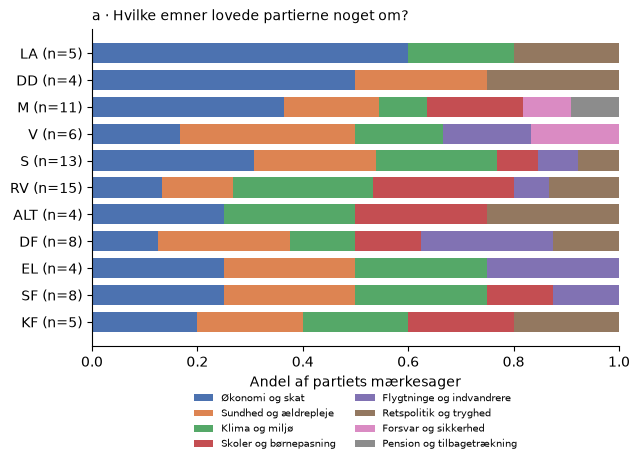

In [68]:
KATEGORIER = ["Økonomi og skat", "Sundhed og ældrepleje", "Klima og miljø", "Skoler og børnepasning",
              "Flygtninge og indvandrere", "Retspolitik og tryghed", "Forsvar og sikkerhed", "Pension og tilbagetrækning"]
KAT_FARVER = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]

andel = pd.crosstab(pol["party_code"], pol["kategori"], normalize="index").reindex(index=PARTIER, columns=KATEGORIER, fill_value=0)
antal = pol["party_code"].value_counts()
raekkefoelge = list(andel.max(axis=1).sort_values().index)      # mest fokuserede parti nederst


def tegn_panel_a(ax):
    venstre = np.zeros(len(raekkefoelge))
    for kat, farve in zip(KATEGORIER, KAT_FARVER):
        v = andel.loc[raekkefoelge, kat].values
        ax.barh(range(len(raekkefoelge)), v, left=venstre, color=farve, height=0.75, label=kat)
        venstre += v
    ax.set_yticks(range(len(raekkefoelge)), [f"{p} (n={antal[p]})" for p in raekkefoelge])
    ax.set_xlim(0, 1); ax.set_xlabel("Andel af partiets mærkesager")
    ax.set_title("a · Hvilke emner lovede partierne noget om?", fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=7, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))


fig, ax = plt.subplots(figsize=(6.5, 4.8)); tegn_panel_a(ax); plt.tight_layout(); plt.show()

## 5 · Panel b: hvad lovede de konkret?

For hvert parti vises de seks ord med højest TF-IDF-vægt (søjlelængde = vægt i forhold til partiets øverste ord): ord, som partiet bruger meget, og som få andre partier bruger. Det er partiets *karakteristiske* løfter, ikke de hyppigste ord.

In [69]:
ORD = np.array(vec.get_feature_names_out())
N_ORD = 6


def top_ord(p, n=N_ORD):
    r = X[PARTIER.index(p)].toarray().ravel()
    idx = np.argsort(r)[::-1][:n]
    return list(ORD[idx]), list(r[idx])


for p in PARTIER:
    print(f"{p:>3}:", ", ".join(top_ord(p)[0]))

  S: fængselsbetjente, bandernes, kriminalitet, målet, nedbringe, drikkevand
  V: klimakampen, havvind, forrest, regeringen, beskæftigelsesindsats, aftale
  M: organiseret, kultur, velfærden, udenlandsk, skat, fremtidens
 SF: minimumsnormeringer, mistrivsel, tilbud, stoffer, økologisk, demens
 DD: barsel, faglært, familierne, erhvervsskolerne, studerende, uger
 LA: retssikkerheden, skattetryk, borgerne, retssikkerhed, skat, sektor
 KF: dagtilbud, loven, kriminalitet, lavere, parallelsamfund, lokalt
 EL: ligeløn, fair, animalske, ramt, socialistisk, indkomster
 DF: kriminalitet, marked, kriminelle, statsborgerretskonventionen, banderne, europæiske
 RV: rent, reformer, lærere, tilliden, åbenhed, mistrivsel
ALT: landbrug, bæredygtige, mad, jord, videregående, fonden


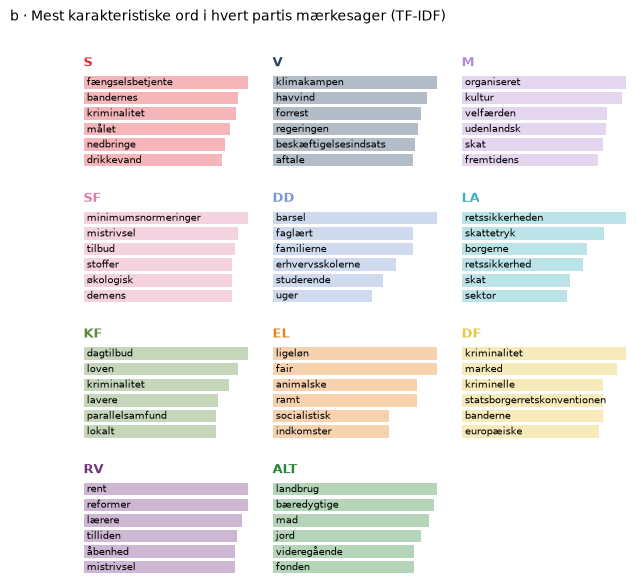

In [70]:
def tegn_panel_b(fig, gs, ncol=3):
    for k, p in enumerate(PARTIER):
        ax = fig.add_subplot(gs[k // ncol, k % ncol])
        ord_, vaegt = top_ord(p)
        vaegt = np.array(vaegt) / max(vaegt)                # relativ vægt inden for partiet
        ax.barh(range(len(ord_)), vaegt, color=FARVER[p], alpha=0.35, height=0.8)
        for i, w in enumerate(ord_):                         # ordet skrives oven på søjlen
            ax.text(0.02, i, w, va="center", ha="left", fontsize=7)
        ax.set_xlim(0, 1); ax.set_ylim(len(ord_) - 0.5, -0.5)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(p, fontsize=9, fontweight="bold", color=FARVER[p], loc="left")
        ax.spines[["top", "right", "bottom", "left"]].set_visible(False)


fig = plt.figure(figsize=(7, 6.5))
gs = fig.add_gridspec(4, 3, hspace=0.45, wspace=0.15)
tegn_panel_b(fig, gs)
fig.suptitle("b · Mest karakteristiske ord i hvert partis mærkesager (TF-IDF)", fontsize=10, x=0.02, ha="left")
fig.savefig("fig1b_karakteristiske_ord.pdf", bbox_inches="tight")
fig.savefig("fig1b_karakteristiske_ord.png", dpi=300, bbox_inches="tight")
plt.show()

## 6 · Panel c (valgfri): byg tekstnetværket (backbone)

For hvert parti beholder vi de *k* partier, det ligner mest. En kant kommer med, hvis den er blandt *mindst ét* af de to partiers top-*k*. Kantvægt = cosine-lighed.

In [71]:
def tekstnetvaerk(sim, k=3):
    G = nx.Graph()
    G.add_nodes_from(sim.index)
    for p in sim.index:
        for q, w in sim.loc[p].drop(p).nlargest(k).items():
            G.add_edge(p, q, weight=float(w))
    return G


K = 3
G = tekstnetvaerk(sim, K)
print(G.number_of_nodes(), "noder,", G.number_of_edges(), "kanter")
print("Grad pr. parti:", dict(sorted(G.degree(), key=lambda t: -t[1])))

11 noder, 27 kanter
Grad pr. parti: {'S': 10, 'SF': 9, 'RV': 9, 'DF': 5, 'V': 3, 'M': 3, 'DD': 3, 'LA': 3, 'KF': 3, 'EL': 3, 'ALT': 3}


## 7 · Tegn panel c

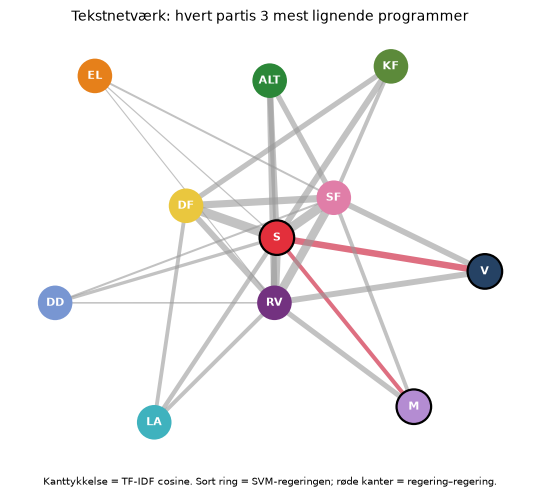

In [72]:
def tegn(G, ax, titel, seed=4):
    pos = nx.spring_layout(G, weight="weight", seed=seed)
    w = np.array([G[u][v]["weight"] for u, v in G.edges()])
    bredde = 0.8 + 6 * (w - w.min()) / (w.max() - w.min() + 1e-9)
    kantfarve = ["#c8102e" if u in REGERING and v in REGERING else "#9a9a9a" for u, v in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, width=bredde, alpha=0.6, edge_color=kantfarve)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[FARVER[p] for p in G], node_size=620,
                           edgecolors=["k" if p in REGERING else "none" for p in G], linewidths=1.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="white", font_weight="bold")
    ax.set_title(titel, fontsize=10)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(5.5, 5))
tegn(G, ax, f"Tekstnetværk: hvert partis {K} mest lignende programmer")
fig.text(0.5, 0.02, "Kanttykkelse = TF-IDF cosine. Sort ring = SVM-regeringen; røde kanter = regering–regering.",
         ha="center", fontsize=7)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("fig1c_tekstnetvaerk.pdf", bbox_inches="tight")
fig.savefig("fig1c_tekstnetvaerk.png", dpi=300, bbox_inches="tight")
plt.show()

## 8 · Robusthedscheck: ændrer netværket sig med *k*?

Antallet af kanter er et valg. Hvis strukturen er nogenlunde den samme for k = 2, 3 og 4, kan I skrive det i captionen.

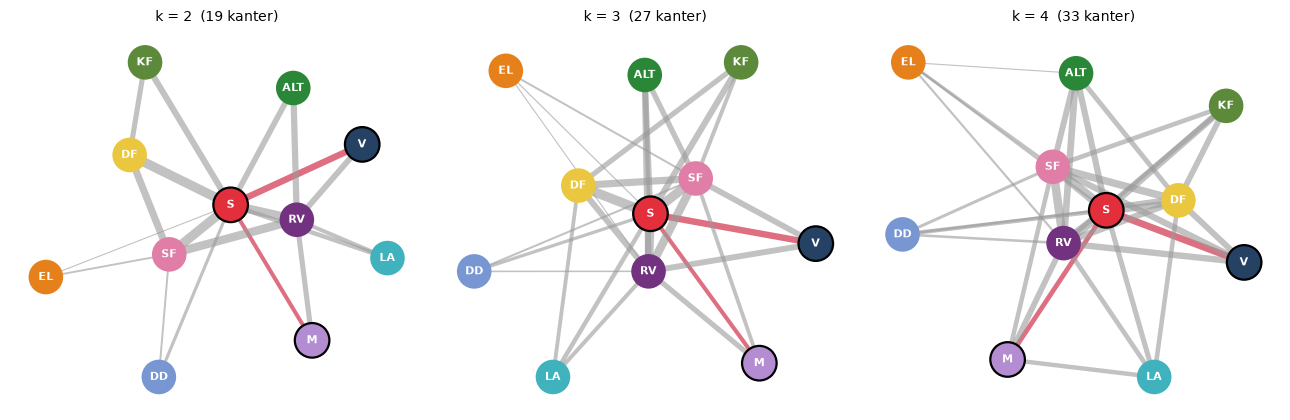

k=2: 19 af 27 kanter fra k=3 går igen
k=4: 27 af 27 kanter fra k=3 går igen


In [73]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, k in zip(axes, [2, 3, 4]):
    Gk = tekstnetvaerk(sim, k)
    tegn(Gk, ax, f"k = {k}  ({Gk.number_of_edges()} kanter)")
plt.tight_layout(); plt.show()

# Hvor mange af k=3-kanterne findes også ved k=2 og k=4?
E3 = {frozenset(e) for e in tekstnetvaerk(sim, 3).edges()}
for k in [2, 4]:
    Ek = {frozenset(e) for e in tekstnetvaerk(sim, k).edges()}
    print(f"k={k}: {len(E3 & Ek)} af {len(E3)} kanter fra k=3 går igen")

## 9 · Check: hvilke ord gør partierne ens?

Står der emneord (fx *kriminalitet*, *politi*), måler ligheden emner. Står der fyldord (fx *støtte*, *stop*, *giv*), skal de på stoplisten, og I kører igen fra afsnit 2 (listen `ekstra`).

In [74]:
ord_liste = np.array(vec.get_feature_names_out())


def faelles_ord(a, b, n=10):
    i, j = PARTIER.index(a), PARTIER.index(b)
    bidrag = X[i].multiply(X[j]).toarray().ravel()
    return list(ord_liste[np.argsort(bidrag)[::-1][:n]])


for (a, b), v in par.head(5).items():
    print(f"{a}–{b} ({v:.2f}):", ", ".join(faelles_ord(a, b)))

S–DF (0.48): kriminalitet, banderne, kriminelle, fængselsbetjente, indsatte, politi, afgiften, politiet, færdes, opgaver
S–SF (0.47): drikkevand, pårørende, landbrug, stoffer, børn, landbruget, børnene, afsat, udspil, opgaver
S–RV (0.45): rent, drikkevand, målet, nedbringe, stærkt, løse, uddannelser, ambition, kolleger, forslag
SF–RV (0.44): mistrivsel, bæredygtigt, børn, kæmper, drikkevand, mistrives, diagnoser, løfte, natur, skov
SF–DF (0.39): børn, arbejder, ønsker, holland, ligestilling, gennem, dyr, ældrepleje, problemet, ret


## 10 · Saml figur 1 til paperet

Panel a og b side om side på to spalters bredde (17,8 cm). Panel c gemmes for sig, så I kan vælge, om den skal med her eller i figur 3.

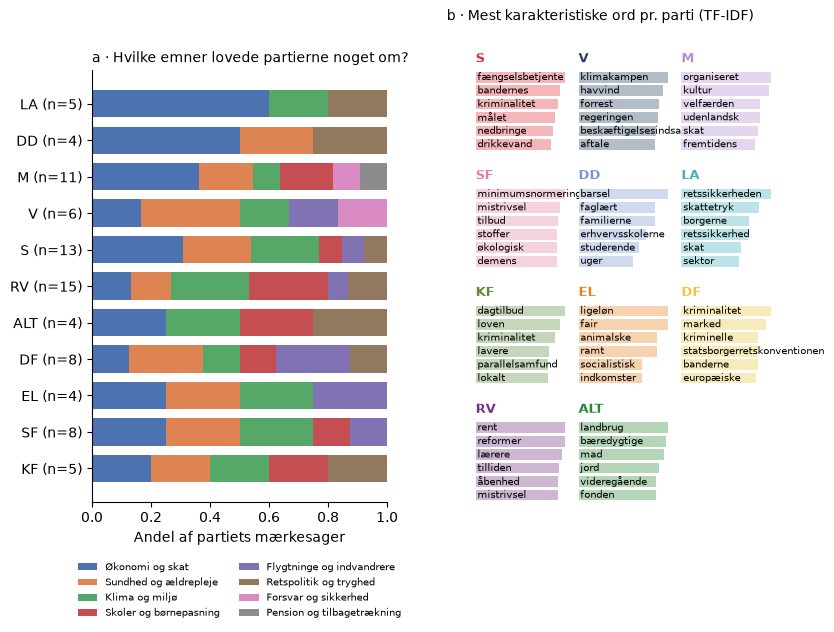

In [75]:
fig = plt.figure(figsize=(17.8 / 2.54 * 1.25, 5.6))
outer = fig.add_gridspec(1, 2, width_ratios=[1, 1], wspace=0.3)
tegn_panel_a(fig.add_subplot(outer[0]))
tegn_panel_b(fig, outer[1].subgridspec(4, 3, hspace=0.45, wspace=0.15))
fig.text(0.53, 0.97, "b · Mest karakteristiske ord pr. parti (TF-IDF)", fontsize=10)
fig.savefig("fig1_hvad_lover_de.pdf", bbox_inches="tight")
fig.savefig("fig1_hvad_lover_de.png", dpi=300, bbox_inches="tight")
plt.show()

## 11 · Tabel over mærkesager til Methods eller appendiks

In [76]:
tabel = (pol.sort_values(["party_code", "kategori"])
            .groupby("party_code")
            .agg(antal=("title", "size"), maerkesager=("title", lambda t: "; ".join(t)))
            .reindex(PARTIER))
tabel.to_csv("tabel_maerkesager.csv", encoding="utf-8-sig")
print(tabel.to_string()[:3000])

            antal                                                                                                                                                                                                                                                                                                                                                                                                                                                    maerkesager
party_code                                                                                                                                                                                                                                                                                                                                                                                                                                                                      
S              13                                                     

## 12 · Til captionen

Udfyld tallene i [klammer]:

*What the parties promised. (a) Share of each party's pre-election policy pages by policy area (Internet Archive captures ≤ 31 Oct 2022; n = [83] pages, number per party in brackets). (b) The six terms with the highest TF-IDF weight in each party's pages, i.e. terms the party uses often and few other parties use. Danish stopwords, numerals and party names removed.*

Panel c, hvis den kommer med: *Text network: each party is linked to its three most similar parties (TF-IDF cosine); edge width shows similarity. V and M are both linked to S but not to each other. [19] of the 27 edges remain for k = 2, and all remain for k = 4.*